In [1]:
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
import requests
import json
import time
import numpy as np
from tqdm import tqdm
import sys
from collections import Counter
from itertools import chain
import requests
import re
import pickle
import glob
import anndata as ad
import pandas as pd

## Analyze downloaded gene count files

### Examining example gene count file

In [7]:
example_file_path = "../../data/TCGA_RNAseq_STAR_counts/TCGA-BRCA/ff0f875f-113a-4c0f-8c0a-4259cd496e6d_c58a5583-7b04-4b67-9372-e161e18d7de1.rna_seq.augmented_star_gene_counts.tsv"  # Example gene count file
example_gene_count_df = pd.read_csv(example_file_path, sep='\t', comment="#")
example_gene_count_df  = example_gene_count_df[example_gene_count_df ['gene_id'].str.startswith('ENSG', na=False)]

In [8]:
print("=" * 80)
print("FILE EXAMINATION")
print("=" * 80)
print(f"\nShape: {example_gene_count_df.shape}")
print(f"\nColumns: {example_gene_count_df.columns.tolist()}")

# Remove the N_unmapped, N_multimapping, etc. rows
# These don't have gene_id starting with ENSG
example_df_genes = example_gene_count_df[example_gene_count_df['gene_id'].str.startswith('ENSG', na=False)].copy()

print(f"\nNumber of genes (after filtering): {example_df_genes.shape[0]}")
print(f"\nFirst few genes:")
print(example_df_genes.head())

FILE EXAMINATION

Shape: (60660, 9)

Columns: ['gene_id', 'gene_name', 'gene_type', 'unstranded', 'stranded_first', 'stranded_second', 'tpm_unstranded', 'fpkm_unstranded', 'fpkm_uq_unstranded']

Number of genes (after filtering): 60660

First few genes:
              gene_id gene_name       gene_type  unstranded  stranded_first  \
4  ENSG00000000003.15    TSPAN6  protein_coding        4241            2109   
5   ENSG00000000005.6      TNMD  protein_coding          13               4   
6  ENSG00000000419.13      DPM1  protein_coding        3226            1639   
7  ENSG00000000457.14     SCYL3  protein_coding        1812            1638   
8  ENSG00000000460.17  C1orf112  protein_coding        1306            1387   

   stranded_second  tpm_unstranded  fpkm_unstranded  fpkm_uq_unstranded  
4             2132         44.5418          13.2684             12.6065  
5                9          0.4196           0.1250              0.1188  
6             1587        127.3297          37.92

In [9]:
gene_names = example_gene_count_df['gene_name'].values

In [10]:
print("\n" + "=" * 80)
print("TPM STATISTICS")
print("=" * 80)
print(example_df_genes['tpm_unstranded'].describe())
print(f"\nGenes with TPM > 0: {(example_df_genes['tpm_unstranded'] > 0).sum()}")
print(f"Genes with TPM > 1: {(example_df_genes['tpm_unstranded'] > 1).sum()}")
print(f"Genes with TPM > 10: {(example_df_genes['tpm_unstranded'] > 10).sum()}")


TPM STATISTICS
count    60660.000000
mean        16.485328
std        242.522936
min          0.000000
25%          0.000000
50%          0.082100
75%          2.110825
max      21073.154600
Name: tpm_unstranded, dtype: float64

Genes with TPM > 0: 34992
Genes with TPM > 1: 18100
Genes with TPM > 10: 9793


In [11]:
print("\n" + "=" * 80)
print("TOP 10 EXPRESSED GENES")
print("=" * 80)
top_genes = example_df_genes.nlargest(10, 'tpm_unstranded')[['gene_name', 'gene_type', 'tpm_unstranded']]
print(top_genes.to_string(index=False))


TOP 10 EXPRESSED GENES
gene_name      gene_type  tpm_unstranded
   MT-CO3 protein_coding      21073.1546
   MT-ND4 protein_coding      19749.8694
   MT-CO1 protein_coding      19603.3506
   MT-CO2 protein_coding      16660.3885
  MT-RNR2        Mt_rRNA      16548.6903
     IGKC      IG_C_gene      15441.3177
   MT-ND1 protein_coding      14994.9749
   MT-ND3 protein_coding      13785.2039
   MT-CYB protein_coding      12163.4270
  MT-ATP6 protein_coding      12157.8829


In [12]:
print("\n" + "=" * 80)
print("GENE TYPES DISTRIBUTION")
print("=" * 80)
print(example_df_genes['gene_type'].value_counts().head(10))


GENE TYPES DISTRIBUTION
gene_type
protein_coding                        19962
lncRNA                                16901
processed_pseudogene                  10167
unprocessed_pseudogene                 2614
misc_RNA                               2212
snRNA                                  1901
miRNA                                  1881
TEC                                    1057
snoRNA                                  943
transcribed_unprocessed_pseudogene      939
Name: count, dtype: int64


In [15]:
# Get protein coding genes
protein_coding_genes = example_df_genes[example_df_genes['gene_type'] == 'protein_coding']  
protein_coding_gene_symbols = list(protein_coding_genes['gene_name'].values)
print(f"Number of protein coding genes in TCGA: {len(protein_coding_gene_symbols)}")

Number of protein coding genes in TCGA: 19962


### Create gene_type mapping for all genes

In [9]:
gene_type_map = dict(zip(example_df_genes['gene_name'], example_df_genes['gene_type']))

In [10]:
print(f"Gene types in data:")
print(pd.Series(gene_type_map).value_counts())

Gene types in data:
protein_coding                        19935
lncRNA                                16875
processed_pseudogene                  10159
unprocessed_pseudogene                 2611
miRNA                                  1879
snRNA                                  1837
misc_RNA                               1279
TEC                                    1057
transcribed_unprocessed_pseudogene      934
snoRNA                                  793
transcribed_processed_pseudogene        500
rRNA_pseudogene                         491
IG_V_pseudogene                         187
IG_V_gene                               145
transcribed_unitary_pseudogene          138
TR_V_gene                               106
unitary_pseudogene                       98
TR_J_gene                                79
polymorphic_pseudogene                   48
scaRNA                                   48
rRNA                                     39
IG_D_gene                                37
TR_V_pseudog

In [11]:
protein_coding_genes = [gene for gene, gtype in gene_type_map.items() if gtype == 'protein_coding']
len(protein_coding_genes)

19935

## Format TCGA RNA-Seq

### Aggregate TCGA TPM values into AnnData

In [3]:
data_dir = "../../data/TCGA_RNAseq_STAR_counts/"
project_data_dir = "../../data/TCGA/"
raw_rna_df_file = os.path.join(project_data_dir, "RNA", "TCGA_bulk_RNA_raw_df.pkl")
raw_h5ad_file = os.path.join(project_data_dir, "RNA", "TCGA_bulk_RNA_raw.h5ad")
processed_h5ad_file = os.path.join(project_data_dir, "RNA", "TCGA_bulk_RNA_processed.h5ad")
log1p_processed_h5ad_file = os.path.join(project_data_dir, "RNA", "TCGA_bulk_RNA_processed_log1p.h5ad")

In [13]:
all_sample_data = []

project_dirs = [d for d in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, d)) and d.startswith('TCGA-')]
print(f"Found {len(project_dirs)} TCGA projects\n")

Found 33 TCGA projects



In [14]:
uuid_list = []
for proj in os.listdir(data_dir):
    proj_dir = os.path.join(data_dir, proj)
    if os.path.isdir(proj_dir) and proj.startswith("TCGA-"):
        for f in os.listdir(proj_dir):
            if f.endswith(".tsv") or f.endswith(".txt"):
                uuid = f.split("_")[0]  # extract UUID before first underscore
                if len(uuid) == 36:     # ensure it's a UUID
                    uuid_list.append(uuid)

uuid_set = sorted(set(uuid_list))
print(f"Found {len(uuid_set)} unique UUIDs across all projects")

Found 10517 unique UUIDs across all projects


In [15]:
# Create UUID to TCGA mapping
BASE_API = "https://api.gdc.cancer.gov/"
CHUNK_SIZE = 100
RETRY_LIMIT = 3

def fetch_case_mapping(uuid_chunk):
    filters = {
        "op": "in",
        "content": {"field": "cases.case_id", "value": uuid_chunk}
    }
    params = {
        "filters": json.dumps(filters),
        "format": "JSON",
        "fields": "case_id,submitter_id,samples.submitter_id",
        "size": len(uuid_chunk)
    }
    for attempt in range(RETRY_LIMIT):
        try:
            r = requests.get(BASE_API + "cases", params=params, timeout=60)
            r.raise_for_status()
            hits = r.json()["data"]["hits"]
            return hits
        except requests.exceptions.RequestException as e:
            print(f"Request failed ({e}), retrying ({attempt+1}/{RETRY_LIMIT})...")
            time.sleep(3)
    print(f"Failed after {RETRY_LIMIT} retries.")
    return []

def build_uuid_mapping(all_case_ids):
    all_case_ids = list(all_case_ids)
    mappings = {}
    for i in tqdm(range(0, len(all_case_ids), CHUNK_SIZE), desc="Fetching UUID to TCGA mapping"):
        chunk = all_case_ids[i:i+CHUNK_SIZE]
        hits = fetch_case_mapping(chunk)
        for h in hits:
            case_uuid = h["case_id"]
            case_barcode = h.get("submitter_id")
            sample_barcode = None
            if "samples" in h and h["samples"]:
                sample_barcode = h["samples"][0].get("submitter_id")
            mappings[case_uuid] = sample_barcode or case_barcode
        time.sleep(0.1)
    return mappings

In [16]:
uuid_to_barcode = build_uuid_mapping(uuid_set)

Fetching UUID to TCGA mapping: 100%|██████████| 106/106 [01:28<00:00,  1.20it/s]


In [17]:
mapping_df = pd.DataFrame(list(uuid_to_barcode.items()), columns=["case_uuid", "tcga_barcode"])
mapping_df.to_csv("uuid_to_tcga_mapping.csv", index=False)
print("Saved uuid_to_tcga_mapping.csv")

Saved uuid_to_tcga_mapping.csv


In [18]:
not_fully_downloaded_projects = []
for project in project_dirs:
    path = os.path.join(data_dir, project, "rnaSeq_sample_table.csv")
    if not os.path.exists(path):
        not_fully_downloaded_projects.append(project)

print("Projects not fully downloaded:", not_fully_downloaded_projects)        

Projects not fully downloaded: []


In [19]:
# Collect all samples across projects
all_samples = []
for proj in project_dirs:
    project_dir = os.path.join(data_dir, proj)
    sample_table = pd.read_csv(os.path.join(project_dir, "rnaSeq_sample_table.csv"))
    cancer_type = proj.replace('TCGA-', '')
    
    for idx, row in sample_table.iterrows():
        all_samples.append({
            'project': proj,
            'project_dir': project_dir,
            'cancer_type': cancer_type,
            'sample_id': row['sample_id'],
            'file_name': row['file_name']
        })

In [20]:
# Process samples
for sample_info in tqdm(all_samples, desc="Processing samples"):
    sample_id = sample_info['sample_id']
    file_name = sample_info['file_name']
    project_dir = sample_info['project_dir']
    cancer_type = sample_info['cancer_type']
    
    sample_file = os.path.join(project_dir, f"{sample_id}_{file_name}")
    
    df = pd.read_csv(sample_file, sep="\t", comment='#')
    df = df[df['gene_id'].str.startswith('ENSG', na=False)]

    tpm_col = 'tpm_unstranded'
    
    sample_row = {
        'cancer_type': cancer_type,
        'sample_id': sample_id
    }
    
    # Add TPM values for each gene (using gene_name as column)
    for gene_name, tpm_value in zip(df['gene_name'], df[tpm_col]):
        sample_row[gene_name] = tpm_value
    
    all_sample_data.append(sample_row)

Processing samples: 100%|██████████| 11505/11505 [57:36<00:00,  3.33it/s] 


In [23]:
combined_tpm = pd.DataFrame(all_sample_data)

In [68]:
# Save raw DataFrame
with open(raw_rna_df_file , 'wb') as f:
    pickle.dump(combined_tpm, f)

In [76]:
# Assuming combined_tpm has a column 'sample_id' with UUIDs
# and mapping_df has 'case_uuid' -> 'tcga_barcode'

# Map sample_id to TCGA barcode
merged_combined_tpm = combined_tpm.merge(mapping_df, left_on='sample_id', right_on='case_uuid', how='left')

# Columns for AnnData
gene_columns = [c for c in merged_combined_tpm.columns if c not in ['cancer_type', 'sample_id', 'case_uuid', 'tcga_barcode']]

X = merged_combined_tpm[gene_columns].astype('float32').values  # expression matrix

# obs DataFrame
obs = merged_combined_tpm[['sample_id', 'tcga_barcode', 'cancer_type']].copy()
obs.rename(columns={
    'tcga_barcode': 'cases.submitter_id',
    'cancer_type': 'project.project_id'
}, inplace=True)

# Set project.project_id format
obs['project.project_id'] = obs['project.project_id'].apply(lambda x: f'TCGA-{x}' if not x.startswith('TCGA-') else x)

# Set index as filename (original UUID-based sample_id)
obs.index = obs['sample_id']

# var DataFrame
var = pd.DataFrame(index=gene_columns)
var['gene_symbol'] = var.index

# Create AnnData
adata = ad.AnnData(X=X, obs=obs, var=var)

/data/rbg/users/ashyamal/miniconda3/envs/rna_modeling/lib/python3.12/site-packages/anndata/_core/anndata.py:1792: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [77]:
print(adata)

AnnData object with n_obs × n_vars = 11505 × 59427
    obs: 'sample_id', 'cases.submitter_id', 'project.project_id'
    var: 'gene_symbol'


In [78]:
print(adata.obs[["cases.submitter_id", "project.project_id"]].head())

                                     cases.submitter_id project.project_id
sample_id                                                                 
1dbd7b0e-9234-47d9-bdca-5b17f5af619b   TCGA-VD-AA8N-01Z           TCGA-UVM
56ed4ea2-18ce-48d4-bf72-9ffabe576ca9   TCGA-WC-A881-01Z           TCGA-UVM
b224e42d-8b6d-4578-963c-bf528b954900   TCGA-VD-AA8P-10A           TCGA-UVM
5e54122f-1c4d-45cc-8842-cd1c1df0eed8   TCGA-V4-A9EH-10A           TCGA-UVM
1a2ce30c-5891-4bf6-8c97-6d1f34d4fe48   TCGA-VD-A8KM-10C           TCGA-UVM


In [79]:
adata.obs['project.project_id'].nunique()

33

In [80]:
adata.obs = adata.obs.drop(columns=['sample_id'])

In [81]:
# Remove sample type suffixes from cases.submitter_id
adata.obs["cases.submitter_id"] = adata.obs["cases.submitter_id"].str[:-4]

In [83]:
adata.write(raw_h5ad_file)

In [39]:
print("\n" + "="*50)
print("SUMMARY")
print("="*50)
print(f"Total samples: {combined_tpm.shape[0]}")
print(f"Total genes: {len(gene_columns)}")
print(f"Shape: {combined_tpm.shape}")
print(f"\nCancer type distribution:")



SUMMARY
Total samples: 11505
Total genes: 59427
Shape: (11505, 59429)

Cancer type distribution:


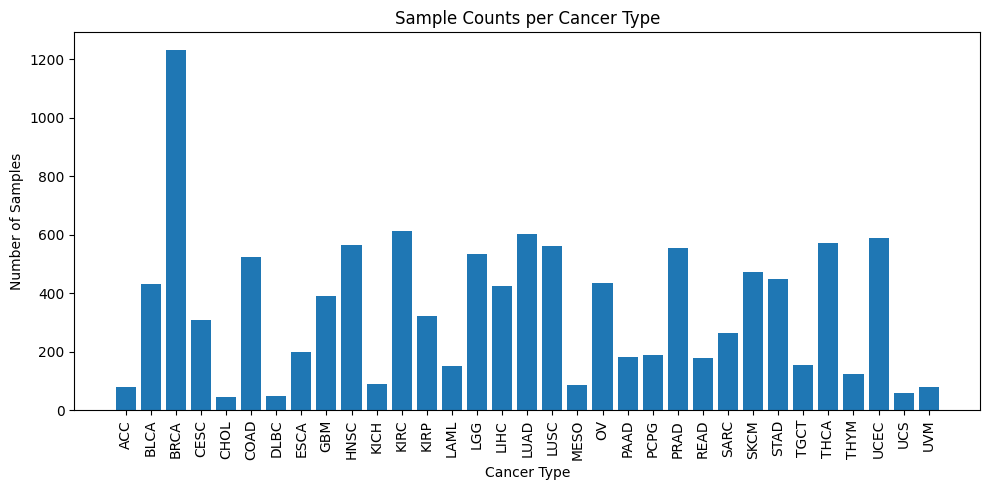

In [40]:
counts = combined_tpm['cancer_type'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=90)
plt.xlabel("Cancer Type")
plt.ylabel("Number of Samples")
plt.title("Sample Counts per Cancer Type")
plt.tight_layout()
plt.show()

In [41]:
missing_values = combined_tpm.isnull().sum().sum()
print(f"\nMissing values: {missing_values}")


Missing values: 0


In [43]:
# Identify duplicate genes
duplicated_genes = combined_tpm.columns[combined_tpm.columns.duplicated()].tolist()
len(duplicated_genes)

0

In [44]:
combined_tpm.head()

,cancer_type,sample_id,TSPAN6,TNMD,DPM1,SCYL3,C1orf112,FGR,CFH,FUCA2,...,AL451106.1,AC092910.4,AC073611.1,AC136977.1,AC078856.1,AC008763.4,AL592295.6,AC006486.3,AL391628.1,AP006621.6
0,UVM,1dbd7b0e-9234-47d9-bdca-5b17f5af619b,10.8873,0.0000,19.4404,1.5856,0.5256,1.4118,1.0599,28.6669,...,0.0,0.0,0.4309,0.0,0.0,0.0,4.9072,0.0,0.0000,0.2436
1,UVM,56ed4ea2-18ce-48d4-bf72-9ffabe576ca9,11.1256,0.0000,34.4112,2.5135,0.6800,1.4220,0.7044,16.7763,...,0.0,0.0,0.4603,0.0,0.0,0.0,6.2561,0.0,0.0260,1.3384
2,UVM,b224e42d-8b6d-4578-963c-bf528b954900,13.6243,0.0407,33.9519,4.4457,2.1608,0.4435,1.3383,61.8710,...,0.0,0.0,0.0842,0.0,0.0,0.0,5.7443,0.0,0.0000,0.4286
3,UVM,5e54122f-1c4d-45cc-8842-cd1c1df0eed8,42.5252,0.0000,109.6773,4.0478,2.2331,1.0471,1.2791,72.6535,...,0.0,0.0,0.1371,0.0,0.0,0.0,7.0032,0.0,0.0162,0.6820
4,UVM,1a2ce30c-5891-4bf6-8c97-6d1f34d4fe48,10.9346,0.0298,37.6654,4.3032,1.1279,15.2382,9.4638,62.5059,...,0.0,0.0,0.1622,0.0,0.0,0.0,3.9699,0.0,0.0457,1.0217


## Processing clinical data

In [45]:
clinical_data_dir = "../../data/expanded_TCGA_clinical_data/"
clinical_files = glob.glob(os.path.join(clinical_data_dir, "TCGA-*_clinical.csv"))
survival_output_file = os.path.join(project_data_dir, "clinical_data_prog_rec_death.csv")
clinical_output_file = os.path.join(project_data_dir, "clinical.tsv")

In [46]:
len(clinical_files)

33

In [47]:
# Build clinical_data_prog_rec_death.csv (survival/progression outcome data)
def extract_numeric_values(series):
    """Extract numeric values from a series, handling empty strings and NaNs"""
    values = []
    for val in series:
        if pd.isna(val) or val == '' or val == 'nan':
            continue
        try:
            num_val = float(val)
            if num_val >= 0:  # Only positive values
                values.append(num_val)
        except (ValueError, TypeError):
            continue
    return values

all_records = []

for file in tqdm(clinical_files, desc="Processing files"):
    try:
        df = pd.read_csv(file)
        
        project_id = os.path.basename(file).replace('_clinical.csv', '')
        patient_col = 'cases.submitter_id' if 'cases.submitter_id' in df.columns else 'submitter_id'
        
        for patient_id, group in df.groupby(patient_col):
            
            # ========================================
            # Extract progression/recurrence days
            # ========================================
            prog_rec_days = []
            
            # From follow-ups - numeric fields
            if 'follow_ups.days_to_progression' in df.columns:
                vals = extract_numeric_values(group['follow_ups.days_to_progression'])
                prog_rec_days.extend(vals)
            
            if 'follow_ups.days_to_recurrence' in df.columns:
                vals = extract_numeric_values(group['follow_ups.days_to_recurrence'])
                prog_rec_days.extend(vals)
            
            # Check qualitative field 'follow_ups.progression_or_recurrence' == 'Yes'
            if 'follow_ups.progression_or_recurrence' in df.columns and 'follow_ups.days_to_follow_up' in df.columns:
                yes_rows = group[group['follow_ups.progression_or_recurrence'] == 'Yes']
                if len(yes_rows) > 0:
                    vals = extract_numeric_values(yes_rows['follow_ups.days_to_follow_up'])
                    prog_rec_days.extend(vals)
            
            # ========================================
            # Extract death days
            # ========================================
            death_days = []
            
            # From demographic.days_to_death ONLY
            if 'demographic.days_to_death' in df.columns:
                vals = extract_numeric_values(group['demographic.days_to_death'])
                death_days.extend(vals)
            
            # ========================================
            # Combine progression/recurrence AND death
            # ========================================
            all_event_days = prog_rec_days + death_days
            
            if len(all_event_days) > 0:
                days_to_progression_recurrence = min(all_event_days)
                progression_recurrence_event = 1
            else:
                days_to_progression_recurrence = np.nan
                progression_recurrence_event = 0
            
            # ========================================
            # Extract max follow-up days
            # ========================================
            follow_up_days = []
            
            # From follow_ups.days_to_follow_up ONLY
            if 'follow_ups.days_to_follow_up' in df.columns:
                vals = extract_numeric_values(group['follow_ups.days_to_follow_up'])
                follow_up_days.extend(vals)
            
            # Include death days in follow-up
            follow_up_days.extend(death_days)
            
            # Take the maximum
            if len(follow_up_days) > 0:
                max_follow_up_days = max(follow_up_days)
            else:
                max_follow_up_days = np.nan
            
            record = {
                'patient_id': patient_id,
                'project_id': project_id,
                'days_to_progression_recurrence': days_to_progression_recurrence,
                'max_follow_up_days': max_follow_up_days,
                'progression_recurrence_event': progression_recurrence_event
            }
            
            all_records.append(record)
            
    except Exception as e:
        print(f"Error processing {file}: {e}")
        continue

result_df = pd.DataFrame(all_records)

# Remove 0-day events
zero_day_event_mask = (
    (result_df['progression_recurrence_event'] == 1) &
    (result_df['days_to_progression_recurrence'] == 0.0)
)

num_removed = zero_day_event_mask.sum()
print(f"\nRemoving {num_removed} patients with 0-day events")

result_df = result_df[~zero_day_event_mask].copy()

# Sort by project_id and patient_id
result_df = result_df.sort_values(['project_id', 'patient_id']).reset_index(drop=True)

result_df.to_csv(survival_output_file, index=True)

print(f"\nSummary:")
print(f"Total patients: {len(result_df)}")
print(f"Patients with progression/recurrence/death: {result_df['progression_recurrence_event'].sum()}")
print(f"Patients without event (censored): {(1 - result_df['progression_recurrence_event']).sum()}")
print(f"Patients with NaN max_follow_up_days: {result_df['max_follow_up_days'].isna().sum()}")
print(f"\nOutput saved to: {survival_output_file}")

Processing files:   0%|          | 0/33 [00:00<?, ?it/s]/tmp/ipykernel_2388816/2580586037.py:20: DtypeWarning: Columns (77) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)
Processing files:   3%|▎         | 1/33 [00:00<00:30,  1.04it/s]/tmp/ipykernel_2388816/2580586037.py:20: DtypeWarning: Columns (8,18,26,40,41,79) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)
Processing files:   6%|▌         | 2/33 [00:01<00:20,  1.52it/s]/tmp/ipykernel_2388816/2580586037.py:20: DtypeWarning: Columns (8,27,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)
Processing files:  30%|███       | 10/33 [00:03<00:07,  3.10it/s]/tmp/ipykernel_2388816/2580586037.py:20: DtypeWarning: Columns (72,74,77,81,84) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)
Processing files:  33%|███▎      | 11/33 [00:0


Removing 43 patients with 0-day events

Summary:
Total patients: 11385
Patients with progression/recurrence/death: 4829
Patients without event (censored): 6556
Patients with NaN max_follow_up_days: 209

Output saved to: ../../data/TCGA/clinical_data_prog_rec_death.csv


In [48]:
# Create clinical.tsv by aggregating all downloaded clinical files
all_dfs = []

for file in tqdm(clinical_files, desc="Processing files"):
    try:
        df = pd.read_csv(file)
        all_dfs.append(df)
    except Exception as e:
        print(f"Error processing {file}: {e}")
        continue

print("\nConcatenating all dataframes...")
combined_df = pd.concat(all_dfs, ignore_index=True)

print(f"Total rows: {len(combined_df)}")
print(f"Total columns: {len(combined_df.columns)}")

# Replace empty strings and NaN with '--'
print("\nReplacing NaN and empty strings with '--'...")
combined_df = combined_df.fillna("'--")
combined_df = combined_df.replace('', "'--")
combined_df = combined_df.replace('nan', "'--")

print(f"\nSaving to {clinical_output_file}...")
combined_df.to_csv(clinical_output_file, sep='\t', index=False)

print("\nFirst 5 rows preview:")
print(combined_df.head())

print("\nColumn names:")
print(list(combined_df.columns))

print(f"\nSuccess! File saved to: {clinical_output_file}")
print(f"Total patients: {combined_df['cases.submitter_id'].nunique()}")
print(f"Total projects: {combined_df['project.project_id'].nunique()}")
print(f"Projects: {sorted(combined_df['project.project_id'].unique())}")

Processing files:   0%|          | 0/33 [00:00<?, ?it/s]/tmp/ipykernel_2388816/1002311890.py:6: DtypeWarning: Columns (77) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)
Processing files:   3%|▎         | 1/33 [00:00<00:08,  3.62it/s]/tmp/ipykernel_2388816/1002311890.py:6: DtypeWarning: Columns (8,18,26,40,41,79) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)
Processing files:   6%|▌         | 2/33 [00:00<00:07,  3.92it/s]/tmp/ipykernel_2388816/1002311890.py:6: DtypeWarning: Columns (8,27,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)
Processing files:  30%|███       | 10/33 [00:01<00:02,  9.14it/s]/tmp/ipykernel_2388816/1002311890.py:6: DtypeWarning: Columns (72,74,77,81,84) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)
/tmp/ipykernel_2388816/1002311890.py:6: DtypeWarni


Concatenating all dataframes...
Total rows: 394140
Total columns: 187

Replacing NaN and empty strings with '--'...

Saving to ../../data/TCGA/clinical.tsv...

First 5 rows preview:
                          cases.case_id cases.submitter_id project.project_id  \
0  fb9bafa5-7133-4955-8156-4eb6763dc8e1       TCGA-B0-5695          TCGA-KIRC   
1  fb9bafa5-7133-4955-8156-4eb6763dc8e1       TCGA-B0-5695          TCGA-KIRC   
2  fb9bafa5-7133-4955-8156-4eb6763dc8e1       TCGA-B0-5695          TCGA-KIRC   
3  fb9bafa5-7133-4955-8156-4eb6763dc8e1       TCGA-B0-5695          TCGA-KIRC   
4  fb9bafa5-7133-4955-8156-4eb6763dc8e1       TCGA-B0-5695          TCGA-KIRC   

  demographic.race demographic.gender   demographic.ethnicity  \
0            white             female  not hispanic or latino   
1            white             female  not hispanic or latino   
2            white             female  not hispanic or latino   
3            white             female  not hispanic or latino   
4    

In [49]:
clinical_tsv = pd.read_csv(clinical_output_file, sep='\t')

/tmp/ipykernel_2388816/737137623.py:1: DtypeWarning: Columns (8,9,11,15,22,40,45) have mixed types. Specify dtype option on import or set low_memory=False.
  clinical_tsv = pd.read_csv(clinical_output_file, sep='\t')


In [50]:
len(clinical_tsv.columns)

187

## Process TCGA RNA-seq

### Filter TCGA RNA-seq data based on presence of clinical data

In [84]:
outcomes_df = pd.read_csv(survival_output_file)

In [85]:
len(outcomes_df)

11385

In [86]:
outcomes_df.patient_id.nunique()

11385

In [87]:
len(adata.obs["cases.submitter_id"])

11505

In [88]:
valid_patient_ids = set(outcomes_df["patient_id"].values)

In [89]:
processed_adata = adata[adata.obs["cases.submitter_id"].isin(valid_patient_ids)].copy()

/data/rbg/users/ashyamal/miniconda3/envs/rna_modeling/lib/python3.12/site-packages/anndata/_core/anndata.py:1792: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [90]:
print(processed_adata)

AnnData object with n_obs × n_vars = 11464 × 59427
    obs: 'cases.submitter_id', 'project.project_id'
    var: 'gene_symbol'


### Removing duplicate aliquots from TCGA RNA-seq data

In [91]:
processed_adata.obs_names.duplicated().sum()

np.int64(986)

In [92]:
if processed_adata.obs_names.duplicated().any():
    print(f"Found {processed_adata.obs_names.duplicated().sum()} duplicate samples. Removing duplicates.")
    processed_adata = processed_adata[~processed_adata.obs_names.duplicated()].copy()

Found 986 duplicate samples. Removing duplicates.


In [93]:
len(processed_adata)

10478

In [95]:
processed_adata.write(processed_h5ad_file)

### Log transform TCGA RNA-seq data

In [3]:
TCGA_RNA_seq_info = ad.read_h5ad(processed_h5ad_file)
min_expression = 0.1
    
gene_expression = np.array(TCGA_RNA_seq_info.X.mean(axis=0)).flatten() # Look at the average expression value
expressed_genes = gene_expression >= min_expression # Remove those genes that has low expression value on average
    
print(f"Original shape: {gene_expression.shape}")

TCGA_RNA_seq_info_filtered = TCGA_RNA_seq_info[:, expressed_genes].copy()

print(
    f"After minimum expression filter ({min_expression} TPM): {TCGA_RNA_seq_info_filtered.shape}"
)

Original shape: (59427,)
After minimum expression filter (0.1 TPM): (10478, 38578)


In [5]:
print(TCGA_RNA_seq_info_filtered.var.columns)
print(TCGA_RNA_seq_info_filtered.var.head())
print(TCGA_RNA_seq_info_filtered.var_names[:5])

Index(['gene_symbol'], dtype='object')
         gene_symbol
TSPAN6        TSPAN6
TNMD            TNMD
DPM1            DPM1
SCYL3          SCYL3
C1orf112    C1orf112
Index(['TSPAN6', 'TNMD', 'DPM1', 'SCYL3', 'C1orf112'], dtype='object')


In [6]:
# Find highly variable genes using numpy variance
# Log-transform for variance calculation to stabilize variance across expression levels
X_log = np.log1p(TCGA_RNA_seq_info_filtered.X)
if hasattr(X_log, "toarray"):
    X_log = X_log.toarray()

# Per-gene variance across samples
gene_variances = np.var(X_log, axis=0)

# Save results back into AnnData
TCGA_RNA_seq_info_filtered.X = X_log
TCGA_RNA_seq_info_filtered.var["log_variance"] = gene_variances

TCGA_RNA_seq_info_filtered.uns["min_expression_filter"] = min_expression
TCGA_RNA_seq_info_filtered.uns["processing_steps"] = ["filtered_low_expression", "computed_log_variance"]

In [ ]:
# Save
TCGA_RNA_seq_info_filtered.write_h5ad(log1p_processed_h5ad_file)
print(f"Processed TCGA data and saved to {log1p_processed_h5ad_file}")

Processed TCGA data and saved to ../../data/TCGA/RNA/TCGA_bulk_RNA_processed_log1p.h5ad


## Standardize set of genes

In [4]:
processed_adata = ad.read_h5ad(log1p_processed_h5ad_file)

In [21]:
TCGA_genes = processed_adata.var["gene_symbol"].tolist()
TCGA_genes_variance = processed_adata.var["log_variance"].tolist()
TCGA_var = dict(zip(TCGA_genes, TCGA_genes_variance))

In [23]:
len(TCGA_var)

38578

In [24]:
TCGA_protein_coding_genes = [gene for gene in TCGA_genes if gene in protein_coding_gene_symbols]
print(f"Number of protein coding genes in processed TCGA data: {len(TCGA_protein_coding_genes)}")

Number of protein coding genes in processed TCGA data: 17927


In [25]:
# Order selected genes by variability
selected_genes_tcga = {g: TCGA_var[g] for g in TCGA_protein_coding_genes}

selected_genes_tcga = dict(
    sorted(selected_genes_tcga.items(), key=lambda kv: kv[1], reverse=True)
)

print(f"Number of protein coding genes with variance info: {len(selected_genes_tcga)}")

Number of protein coding genes with variance info: 17927


In [26]:
# Save as pickle file
TCGA_genes_path = os.path.join("../../data/TCGA/", "TCGA_genes_ordered_by_variance.pkl")

with open(TCGA_genes_path, 'wb') as f:
    pickle.dump(selected_genes_tcga, f)